# Day 2 - Supervised learning practical tasks
***
These tasks cover linear regression, logistic regression, decision trees, model evaluation and regularization.

## Regression models

You will use [Advertising](https://www.kaggle.com/purbar/advertising-data) Dataset. The dataset contains statistics about the sales of a product in 200 different markets, together with advertising budgets in each of these markets for different media channels: TV, radio and newspaper.
#### Your task will be to:
1. Write evaluation functions (MAE, MSE, SSE, RMSE, MAPE, R2).
2. Analyze the correlation matrix.
3. Predict sales values using linear regression.
4. Evaluate model with written statistical explanatory variables.
5. Perform cross-validation (k-fold).
6. Compare your regression model to a reduced model by removing one of the features.
7. Compare your regression model to regularization models.

Please use your code and visualization results made in previous day for data preparation and explanatory analysis.

In [44]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score 
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import Ridge
from sklearn.linear_model import ElasticNet
from sklearn.metrics import accuracy_score

### 1. Create statistical evaluation functions for regression models

#### 1.1 Create a function that calculates mean absolute error (MAE)

\begin{equation}
MAE = \frac{1}{n} \sum_{i=1}^{n} \left| y_i - \hat{y}_i\right|
\end{equation}

In [2]:
def MAE(y_true, y_pred):
    return np.mean(np.absolute(y_true - y_pred))

#### 1.2 Create a function that calculates mean squared error (MSE)

\begin{equation}
MSE = \frac{1}{n}\cdot SSE
\end{equation}

\begin{equation}
SSE = \sum_{i=1}^n(y_i - \hat{y}_i)^2
\end{equation}

In [3]:
def MSE(y_true, y_pred):
    return np.mean((y_true - y_pred)**2)

#### 1.3 Create a function that calculates root mean squared error (RMSE)

\begin{equation}
RMSE = \sqrt{MSE}
\end{equation}

In [4]:
def RMSE(y_true, y_pred):
    return np.sqrt(MSE(y_true, y_pred))

#### 1.4 Create a function that calculates mean absolute percentage error (MAPE)

\begin{equation}
MAPE = \frac{100}{n} \sum_{i=1}^n \left| \frac{y_i - \hat{y}_i}{y_i} \right|
\end{equation}

In [5]:
def MAPE(y_true, y_pred):
    return 100 * np.mean(np.abs((y_true - y_pred) / y_true))

#### 1.5 Create a function that calculates coefficient of determination $R^2$ using formula

\begin{equation}
R^2 = \frac{SST-SSE}{SST}
\end{equation}

\begin{equation}
SST = \sum_{i=1}^n (y_i - \bar{y})^2
\end{equation}


In [6]:
def R2(y_true, y_pred):
    SST = np.sum((y_true - np.mean(y_true))**2)
    SSE = np.sum((y_true - y_pred)**2)
    return (SST - SSE) / SST

### 2 Use Linear regression model to make predictions and evaluate it with above developed functions. Perform k-fold cross-validation.

#### 2.1 Read and prepare dataset for modelling - split the data in target variable and features.

In [10]:
adv= pd.read_csv("advertising.csv")
adv.head(10)

,Unnamed: 0,TV,Radio,Newspaper,Sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9
5,6,8.7,48.9,75.0,7.2
6,7,57.5,32.8,23.5,11.8
7,8,120.2,19.6,11.6,13.2
8,9,8.6,2.1,1.0,4.8
9,10,199.8,2.6,21.2,10.6


In [13]:
x = adv[['TV','Radio','Newspaper']]
y =adv['Sales']

#### 2.2. Look at the correlation and visualize the data by methods from day 1 by plots of your choice. Write what you observe.

In [14]:
corr = adv[['TV', 'Radio', 'Newspaper', 'Sales']].corr()
corr

,TV,Radio,Newspaper,Sales
TV,1.000000,0.054809,0.056648,0.782224
Radio,0.054809,1.000000,0.354104,0.576223
Newspaper,0.056648,0.354104,1.000000,0.228299
Sales,0.782224,0.576223,0.228299,1.000000


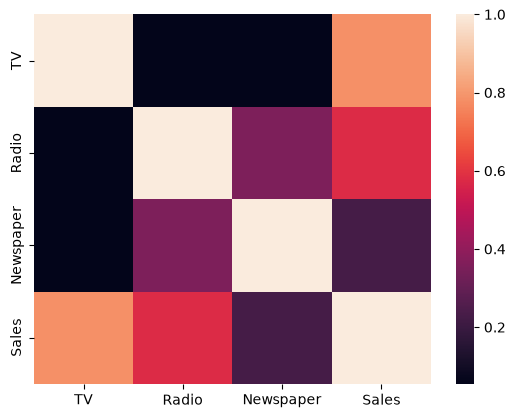

In [16]:
sns.heatmap(corr)
plt.show()

#### 2.3 Separate the target feature, split data in 2:1 proportion (33% form a holdout set, use random_state=17), and preprocess data with [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html#sklearn.preprocessing.StandardScaler).

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    x, y, test_size=0.33, random_state=17
)

In [20]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

#### 2.4 Fit linear regression model, generate predictions and print regression coefficients $b_0$ and $b_1$.

In [22]:
model = LinearRegression(fit_intercept=True)

model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)

print(model.intercept_) # b0
print(model.coef_) # b1


14.022388059701495
[ 3.9675339   2.88155345 -0.07344038]


#### 2.5 Evaluate created model with above functions

In [23]:
print("MAE score:", MAE(y_test, y_pred))
print("MSE score:", MSE(y_test, y_pred))
print("RMSE score:", RMSE(y_test, y_pred))
print("MAPE score:", MAPE(y_test, y_pred))
print("R^2 score:", R2(y_test, y_pred))

MAE score: 1.241490259650847
MSE score: 3.47262996875279
RMSE score: 1.8634993879131783
MAPE score: 18.638804594568974
R^2 score: 0.8515370160992793


#### 2.6 Perform k-fold cross-validation $(k=10)$ and print the mean $R^2$ score to get an overall performance metric.

Please use [cross_val_score](http://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_score.html)
with [r2](https://scikit-learn.org/stable/modules/model_evaluation.html#the-scoring-parameter-defining-model-evaluation-rules) score.

In [25]:
k = 10
kf= KFold(n_splits=k, shuffle=True, random_state=42)
scores = cross_val_score(model, x, y, cv=kf, scoring='r2')

print("Mean R-squared score:", scores.mean())

Mean R-squared score: 0.8731388460886025


#### 2.7. Drop one of the three variables (TV, Radio or Newspaper) and create another model, evaluate it and compare to the first model.

In [27]:
M_new = adv[['TV', 'Radio']]

In [29]:
X_train_new, X_test_new, y_train_new, y_test_new = train_test_split(
    M_new, y, test_size=0.33, random_state=17
)
scaler_new = StandardScaler()

X_train_new_scaled = scaler_new.fit_transform(X_train_new)
X_test_new_scaled = scaler_new.transform(X_test_new)

In [30]:
model2 = LinearRegression(fit_intercept=True)
model2.fit(X_train_new_scaled, y_train_new)
y_pred_new = model2.predict(X_test_new_scaled)

In [31]:
print("MAE:", MAE(y_test_new, y_pred_new))
print("MSE:", MSE(y_test_new, y_pred_new))
print("RMSE:", RMSE(y_test_new, y_pred_new))
print("MAPE:", MAPE(y_test_new, y_pred_new))
print("R-squared:", R2(y_test_new, y_pred_new))

MAE: 1.2423619953941778
MSE: 3.458740998763223
RMSE: 1.859769071353544
MAPE: 18.594637663112877
R-squared: 0.8521308017736854


In [32]:
#comparing to the first model
print("Original model (TV, Radio, Newspaper):")
print("MAE:", MAE(y_test, y_pred))
print("MSE:", MSE(y_test, y_pred))
print("RMSE:", RMSE(y_test, y_pred))
print("MAPE:", MAPE(y_test, y_pred))
print("R-squared:", R2(y_test, y_pred))

print("\nNew model (TV, Radio):")
print("MAE:", MAE(y_test_new, y_pred_new))
print("MSE:", MSE(y_test_new, y_pred_new))
print("RMSE:", RMSE(y_test_new, y_pred_new))
print("MAPE:", MAPE(y_test_new, y_pred_new))
print("R-squared:", R2(y_test_new, y_pred_new))


Original model (TV, Radio, Newspaper):
MAE: 1.241490259650847
MSE: 3.47262996875279
RMSE: 1.8634993879131783
MAPE: 18.638804594568974
R-squared: 0.8515370160992793

New model (TV, Radio):
MAE: 1.2423619953941778
MSE: 3.458740998763223
RMSE: 1.859769071353544
MAPE: 18.594637663112877
R-squared: 0.8521308017736854


### 3. Use regularization models with regularization strength `alpha=1` and compare $MSE$ values with previous models.

#### 3.1 Lasso regression

In [38]:
lasso = Lasso(alpha=1)
lasso.fit(X_train_scaled, y_train)
y_pred_lasso = lasso.predict(X_test_scaled)
mse_lasso = mean_squared_error(y_test, y_pred_lasso)

print("Mean Squared Error:", mse_lasso)
print("Coefficients:", lasso.coef_)

Mean Squared Error: 4.911579294712751
Coefficients: [3.0619592  1.96202634 0.        ]


#### 3.2 Ridge regression

In [41]:
ridge = Ridge(alpha=1)
ridge.fit(X_train_scaled, y_train)
y_pred_ridge = ridge.predict(X_test_scaled)
mse_ridge = mean_squared_error(y_test, y_pred_ridge)

print("Mean Squared Error:", mse_ridge)
print("Coefficients:", ridge.coef_)

Mean Squared Error: 3.4768894774722394
Coefficients: [ 3.93899368  2.85996406 -0.06218255]


#### 3.3 Elastic net regression

Use any `l1_ratio` of your choice.


In [43]:
elastic_net = ElasticNet(alpha=1.0, l1_ratio=0.5)
elastic_net.fit(X_train_scaled, y_train)

y_pred_elastic = elastic_net.predict(X_test_scaled)
mse_elastic = mean_squared_error(y_test, y_pred_elastic)

print("Mean Squared Error:", mse_elastic)
print("Coefficients:", elastic_net.coef_)

Mean Squared Error: 6.8438833201041085
Coefficients: [2.39397459 1.68907463 0.01489489]


#### 3.4 Make conclusions

Ridge regression achieved the lowest MSE of 3.4768894774722394, where it performed best among the three regularization models on the test data.
Lasso regression achieved an MSE of 4.911579294712751 while Elastic Net achieved the highest MSE of 6.8438833201041085.

Here Lasso reduced the Newspaper coefficient to 0 which it excluded this feature from the model, Ridge kept all three features and achieved the best prediction performance and the Elastic Net also kept three feature but MSE was higher

so to conclude based on MSE results, Ridge regression performed best in regularizing the model for it's dataset.


## Classification models

You will use [Diabetes](https://www.kaggle.com/uciml/pima-indians-diabetes-database) dataset. The dataset includes data from 768 women with several medical predictor variables and one target variable. The classification goal is to predict whether or not the patients in the dataset have diabetes.
#### Your task will be to:
1. Write evaluation functions (Accuracy, Precision, Recall, F1).
2. Predict whether or not a patient has diabetes using Logistic regression and Decision Tree Classification models
3. Evaluate both models with written statistical explanatory variables
4. Draw ROC curve and compute AUC
5. Perform cross-validation (k-fold)
6. Analyze the results

Please use your code and visualization results made in previous day for data preparation and explanatory analysis.

### 1. Write statistical evaluation functions for classification models

#### 1.1 Create a function that calculates accuracy

\begin{equation}
Accuracy = \frac{True Positive + True Negative}{True Positive + True Negative + False Positive + False Negative}
\end{equation}

In [ ]:
def accuracy_function(y_true, y_pred):
    TP = sum((y_true == 1) & (y_pred == 1))
    TN = sum((y_true == 0) & (y_pred == 0))
    FP = sum((y_true == 0) & (y_pred == 1))
    FN = sum((y_true == 1) & (y_pred == 0))

    accuracy = (TP + TN) / (TP + TN + FP + FN)
    return accuracy

#### 1.2 Create a function that calculates precision

\begin{equation}
Precision = \frac{True Positive}{True Positive + False Positive}
\end{equation}

In [ ]:
def precision_function(y_true, y_pred):
    TP = sum((y_true == 1) & (y_pred == 1))
    FP = sum((y_true == 0) & (y_pred == 1))

    precision = TP / (TP + FP)
    return precision

#### 1.3  Create a function that calculates recall

\begin{equation}
Recall = \frac{True Positive}{True Positive + False Negative}
\end{equation}

In [54]:
def recall_function(y_true, y_pred):
    TP = sum((y_true ==1) & (y_pred ==1))
    FN = sum((y_true ==1) & (y_pred ==0))

    recall = TP / (TP + FN)
    return recall

#### 1.4 Create a function that calculates $F1$ - score

\begin{equation}
F1 = 2\cdot \frac{Precision \cdot Recall}{Precision + Recall}
\end{equation}

In [55]:
def F1_function(y_true, y_pred):
    precision = precision_function(y_true, y_pred)
    recall = recall_function(y_true, y_pred)
    F1 = 2 * (precision * recall) / (precision + recall)
    return F1

### 2. Use logistic regression to make prediction and evaluate it with above developed functions. Compute ROC and compute AUC. Perform k-fold cross-validation.

#### 2.1 Read and prepare dataset for modelling. Split the data in target variable and features.

Prepare dataset to use it for modelling (you should also replace 0 values in columns `Glucose`, `BloodPressure`,`SkinThickness`,`Insulin`,`BMI` with mean values).

In [ ]:
diab= pd.read_csv("diabetes.csv")
diab.head()
columns = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [58]:
columns = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

for column in columns:
    diab[column] = diab[column].replace(0, np.nan)
    diab[column] = diab[column].fillna(diab[column].mean())

In [59]:
diab[columns].isnull().values.sum()

np.int64(0)

#### 2.2. Look at the correlation and visualize the data by methods from day 1 by plots of your choice. Write what you observe.

In [66]:
df_corr = diab.corr()

correlation_with_target = df_corr['Outcome'].drop('Outcome')

correlation_with_target

Pregnancies                 0.221898
Glucose                     0.492928
BloodPressure               0.166074
SkinThickness               0.215299
Insulin                     0.214411
BMI                         0.311924
DiabetesPedigreeFunction    0.173844
Age                         0.238356
Name: Outcome, dtype: float64

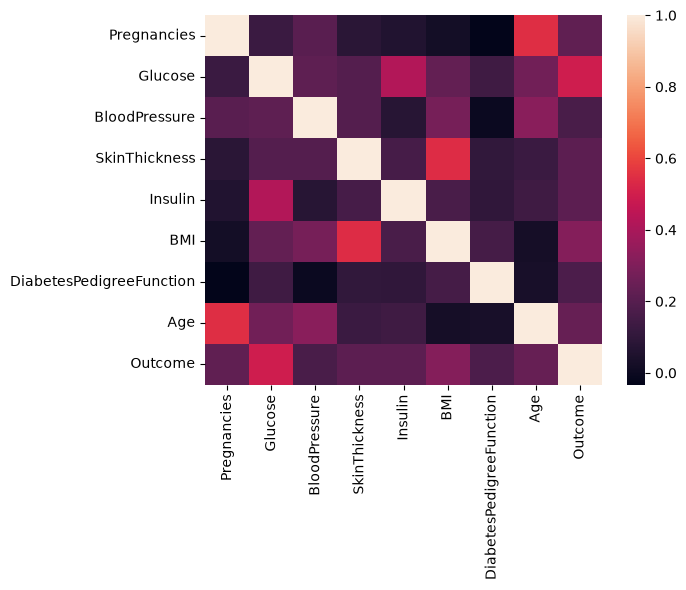

In [67]:
sns.heatmap(df_corr)
plt.show()

OBSERVATION 

The heatmap shows the correlations between the features in the diabetes dataset. Glucose has the strongest positive correlation with Outcome of 0.492928, followed by BMI of 0.311924. Age and Pregnancies also have positive correlations with Outcome. BloodPressure and DiabetesPedigreeFunction have weaker positive correlations. Overall, Glucose appears to have the strongest relationship with the diabetes outcome. The heatmap also shows correlations between the input features themselves.

#### 2.3 Separate the target feature, split data in 2:1 proportion (33% form a holdout set, use random_state=17), and preprocess data with [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html)

In [68]:
x = diab.drop('Outcome', axis=1)
y = diab['Outcome']

In [69]:
X_train, X_test, y_train, y_test = train_test_split(
    x, y, test_size=0.33, random_state=17
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

#### 2.4 Fit logistic regression model, generate predictions

In [71]:
from sklearn.linear_model import LogisticRegression
logreg = LogisticRegression()
logreg.fit(X_train_scaled, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [73]:
y_pred_log = logreg.predict(X_test_scaled)
y_pred_log[:10]

array([0, 1, 0, 0, 0, 0, 0, 1, 1, 1])

#### 2.5 Create a confusion matrix and evaluate created model with above functions

In [74]:
from sklearn.metrics import confusion_matrix

In [79]:
cnf_matrix = confusion_matrix(y_test, y_pred_log)
cnf_matrix

array([[145,  20],
       [ 43,  46]])

In [80]:
print("Accuracy:", accuracy_function(y_test, y_pred_log))
print("Precision:", precision_function(y_test, y_pred_log))
print("Recall:", recall_function(y_test, y_pred_log))
print("F1:", F1_function(y_test, y_pred_log))

Accuracy: 0.7519685039370079
Precision: 0.696969696969697
Recall: 0.5168539325842697
F1: 0.5935483870967742


#### 2.6 Draw a ROC curve and compute Area Under the Curve (AUC)

You can use [roc_auc_score](http://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html) and [RocCurveDisplay.from_predictions](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.RocCurveDisplay.html#sklearn.metrics.RocCurveDisplay.from_predictions).
Check documentation for examples.
For roc_auc_score use predicted probabilities (`predict_proba`), not predicted values. This will align your AUC and ROC curve values.

`predict_proba()` method returns a two-dimensional array. For each instance the predicted class is the class with the maximum probability. To calculate AUC correctly, you need the probability of the positive class (second column, `[:, 1]`).

In [76]:
from sklearn.metrics import roc_auc_score

y_pred_proba = logreg.predict_proba(X_test_scaled)[:, 1]

roc_auc_score(y_test, y_pred_proba)

0.8311201906707525

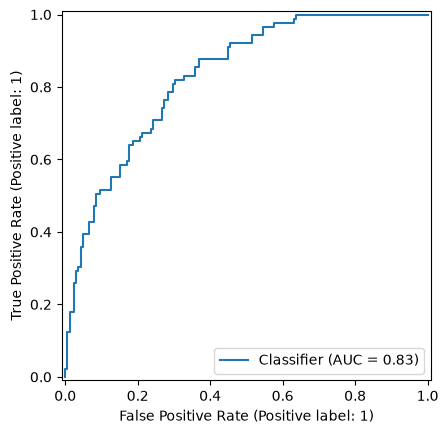

In [78]:
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(y_test, y_pred_proba)
plt.show()

#### 2.7 Perform k-fold cross-validation $(k=10)$ and print the mean accuracy to get an overall performance metric.

Use [cross_val_score](http://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_score.html)
with [accuracy](https://scikit-learn.org/stable/modules/model_evaluation.html#the-scoring-parameter-defining-model-evaluation-rules). Feed your scaled X train and y train data.

In [81]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(logreg, X_train_scaled, y_train, cv=10, scoring='accuracy')

print("Mean accuracy:", scores.mean())

Mean accuracy: 0.764630467571644


### 3. Use Decision tree classification model to make predictions and evaluate it with above developed functions. Draw ROC curve and compute AUC. Perform k-fold cross-validation.

#### 3.1 Create classification tree object, fit model and generate predictions

In [82]:
from sklearn.tree import DecisionTreeClassifier

tree_model = DecisionTreeClassifier(random_state=17)
tree_model.fit(X_train_scaled, y_train)

y_pred_tree = tree_model.predict(X_test_scaled)
y_pred_tree[:10]


array([0, 1, 0, 0, 1, 0, 0, 1, 1, 1])

#### 3.2 Evaluate created model with above functions

In [83]:
print("Accuracy:", accuracy_function(y_test, y_pred_tree))
print("Precision:", precision_function(y_test, y_pred_tree))
print("Recall:", recall_function(y_test, y_pred_tree))
print("F1:", F1_function(y_test, y_pred_tree))


Accuracy: 0.7755905511811023
Precision: 0.6666666666666666
Recall: 0.7191011235955056
F1: 0.6918918918918919


#### 3.3 Draw a ROC curve and compute Area Under the Curve (AUC)

AUC: 0.7625808648280558


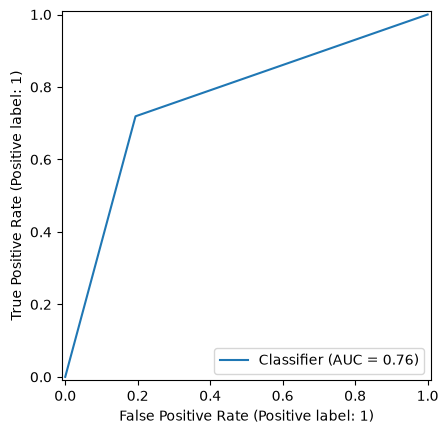

In [84]:
from sklearn.metrics import RocCurveDisplay, roc_auc_score

y_pred_tree_proba = tree_model.predict_proba(X_test_scaled)[:, 1]

print("AUC:", roc_auc_score(y_test, y_pred_tree_proba))

RocCurveDisplay.from_predictions(y_test, y_pred_tree_proba)
plt.show()


#### 3.4 Perform k-fold cross-validation $(k=10)$ and print the mean accuracy to get an overall performance metric.

In [85]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(tree_model, X_train_scaled, y_train, cv=10, scoring="accuracy")

print("Mean accuracy:", scores.mean())


Mean accuracy: 0.7257541478129713


#### 3.5 Make conclusions

The decision tree classifier achieved an accuracy of 0.7756, precision of 0.6667, recall of 0.7191, and F1 score of 0.6919 on the holdout set. The ROC AUC was 0.7626, indicating moderate predictive ability, while the 10-fold cross-validation mean accuracy was 0.7258. This suggests the decision tree performs reasonably well, although it is slightly less stable than the logistic regression model on this dataset.
